# Week 3 - Introduction to Machine Learning (Tasks 2, 3 and 4)
This notebook prepares a dataset for Machine Learning (Task 2), splits and preprocesses it (Task 3) and trains a first ML model (Task 4).

**Dataset:** `Dataset.csv` - a student performance dataset with 204 records: `Study_Hours`, `Attendance` (%), `Previous_Marks`, `Assignment_Score` and the outcome `Result` (Pass / Fail). It is a practice dataset prepared for this assignment and deliberately contains missing values and duplicate rows.

# Task 2: Dataset Preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.width', 120); pd.set_option('display.max_columns', 20)

# 1. Load the dataset
df = pd.read_csv("Dataset.csv")
print("Dataset loaded successfully")

Dataset loaded successfully


### Display the first 5 rows

In [2]:
df.head()

   Student_ID  Study_Hours  Attendance  Previous_Marks  Assignment_Score Result
0        2173          5.3        82.0            27.0              68.0   Pass
1        2090          4.0        55.0            71.0              73.0   Pass
2        2056          1.2        90.0            66.0              70.0   Pass
3        2074          4.3        82.0            79.0              65.0   Pass
4        2159          3.4       100.0            42.0              60.0   Pass

### Check shape and data types

In [3]:
print("Shape (rows, columns):", df.shape)
print()
df.dtypes

Shape (rows, columns): (204, 6)



Student_ID            int64
Study_Hours         float64
Attendance          float64
Previous_Marks      float64
Assignment_Score    float64
Result                  str
dtype: object

### Identify missing values and duplicates

In [4]:
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows      :", df.duplicated().sum())

Missing values per column:
Student_ID          0
Study_Hours         4
Attendance          6
Previous_Marks      5
Assignment_Score    6
Result              0
dtype: int64

Total missing values: 21
Duplicate rows      : 4


### Remove / fill missing values
- **Duplicate rows** are removed because they would count the same student twice.
- **Missing numeric values** are filled with the column **median** (not affected by extreme values), so no student record is lost.

In [5]:
df = df.drop_duplicates()
for col in ["Study_Hours", "Attendance", "Previous_Marks", "Assignment_Score"]:
    df[col] = df[col].fillna(df[col].median())
df = df.reset_index(drop=True)

print("Missing values after cleaning:", df.isnull().sum().sum())
print("Duplicates after cleaning    :", df.duplicated().sum())
print("Shape after cleaning         :", df.shape)
print()
print("Class balance (Result):")
print(df["Result"].value_counts())

Missing values after cleaning: 0
Duplicates after cleaning    : 0
Shape after cleaning         : (200, 6)

Class balance (Result):
Result
Pass    143
Fail     57
Name: count, dtype: int64


### Identify features and target
- **Features (inputs):** `Study_Hours`, `Attendance`, `Previous_Marks`, `Assignment_Score`
- **Target / label (output to predict):** `Result` (Pass / Fail)
- `Student_ID` is only an identifier, so it is **not** used as a feature.

In [6]:
feature_cols = ["Study_Hours", "Attendance", "Previous_Marks", "Assignment_Score"]
X = df[feature_cols]      # features (independent variables)
y = df["Result"]          # target (dependent variable)

print("X shape:", X.shape)
print("y shape:", y.shape)
X.head()

X shape: (200, 4)
y shape: (200,)


   Study_Hours  Attendance  Previous_Marks  Assignment_Score
0          5.3        82.0            27.0              68.0
1          4.0        55.0            71.0              73.0
2          1.2        90.0            66.0              70.0
3          4.3        82.0            79.0              65.0
4          3.4       100.0            42.0              60.0

In [7]:
y.head()

0    Pass
1    Pass
2    Pass
3    Pass
4    Pass
Name: Result, dtype: str

# Task 3: Train-Test Split & Data Preprocessing

### Why do we divide the data into training and testing sets?
A model must be judged on data it has **never seen**. If we tested it on the same data it learned from, it could simply memorise the answers and look perfect, but fail on real students (this is called *overfitting*). So we divide the data:

- **Training data** (usually 70-80%) - the model learns patterns from it.
- **Testing data** (20-30%) - kept hidden until the end to check how well the model predicts new data.

**Flow:** Training Data -> Model Learning -> Testing Data -> Prediction

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       # 20% of data for testing, 80% for training
    random_state=42,     # same split every time we run the code
    stratify=y)          # keep the Pass/Fail ratio the same in both sets

print("Total records   :", len(X))
print("Training set    :", X_train.shape, "->", len(X_train), "records (80%)")
print("Testing set     :", X_test.shape, "->", len(X_test), "records (20%)")
print()
print("Pass/Fail share in training data:")
print(y_train.value_counts(normalize=True).round(2))
print("Pass/Fail share in testing data:")
print(y_test.value_counts(normalize=True).round(2))

Total records   : 200
Training set    : (160, 4) -> 160 records (80%)
Testing set     : (40, 4) -> 40 records (20%)

Pass/Fail share in training data:
Result
Pass    0.71
Fail    0.29
Name: proportion, dtype: float64
Pass/Fail share in testing data:
Result
Pass    0.72
Fail    0.28
Name: proportion, dtype: float64


### Basic preprocessing: feature scaling
The features are on different scales (Study_Hours is about 0-9 whereas Previous_Marks is about 0-100). `StandardScaler` converts every feature to mean 0 and standard deviation 1 so that no feature dominates just because its numbers are larger.

**Important:** the scaler is fitted on the **training data only** and then applied to the test data. Fitting it on test data would leak information from the test set into training.

In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learn mean & std from training data, then scale it
X_test_scaled = scaler.transform(X_test)         # scale test data with the SAME mean & std

print("Mean of training features BEFORE scaling:")
print(X_train.mean().round(2))
print()
print("Mean of training features AFTER scaling :", X_train_scaled.mean(axis=0).round(2))
print("Std  of training features AFTER scaling :", X_train_scaled.std(axis=0).round(2))

Mean of training features BEFORE scaling:
Study_Hours          4.42
Attendance          78.35
Previous_Marks      59.44
Assignment_Score    63.54
dtype: float64

Mean of training features AFTER scaling : [-0.  0. -0. -0.]
Std  of training features AFTER scaling : [1. 1. 1. 1.]


In [10]:
# Label encoding of the target for reference (scikit-learn can also accept text labels directly)
print("Target encoding used internally: Fail = 0, Pass = 1")
pd.DataFrame(X_train_scaled, columns=X.columns).head()

Target encoding used internally: Fail = 0, Pass = 1


   Study_Hours  Attendance  Previous_Marks  Assignment_Score
0    -1.068491   -1.258496        0.445829          0.105137
1    -0.009924    1.475316        0.241827          0.320804
2     0.578169    0.438353       -1.934191         -0.110529
3     0.519359   -0.315802       -0.370178         -0.398084
4     1.342689    1.098238       -0.302178         -0.541862

# Task 4: Build Your First Machine Learning Model
**Option A - Classification using Logistic Regression**

### How Logistic Regression works
Logistic Regression is a **classification** algorithm (despite the name). It calculates a weighted sum of the features (`z = w1*x1 + w2*x2 + ... + b`) and passes it through the **sigmoid function**, which squeezes the result into a probability between 0 and 1. If the probability of *Pass* is 0.5 or more the student is predicted **Pass**, otherwise **Fail**. During training the weights `w` are adjusted until the predictions match the training labels as closely as possible.

In [11]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train_scaled, y_train)        # TRAIN: the model learns from training data
print("Model trained successfully")

Model trained successfully


In [12]:
y_pred = model.predict(X_test_scaled)   # PREDICT on unseen test data

results = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred}, index=y_test.index)
results["Correct?"] = results["Actual"] == results["Predicted"]
results.head(10)

    Actual Predicted  Correct?
110   Fail      Fail      True
104   Pass      Pass      True
68    Fail      Pass     False
52    Pass      Pass      True
66    Pass      Pass      True
187   Pass      Pass      True
148   Pass      Pass      True
3     Pass      Pass      True
14    Pass      Pass      True
59    Pass      Pass      True

In [13]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

acc = accuracy_score(y_test, y_pred)
print("Accuracy:", round(acc * 100, 2), "%")
print()
print("Confusion matrix (rows = actual, columns = predicted) [Fail, Pass]:")
print(confusion_matrix(y_test, y_pred, labels=["Fail", "Pass"]))
print()
print(classification_report(y_test, y_pred))

Accuracy: 90.0 %

Confusion matrix (rows = actual, columns = predicted) [Fail, Pass]:
[[ 8  3]
 [ 1 28]]

              precision    recall  f1-score   support

        Fail       0.89      0.73      0.80        11
        Pass       0.90      0.97      0.93        29

    accuracy                           0.90        40
   macro avg       0.90      0.85      0.87        40
weighted avg       0.90      0.90      0.90        40



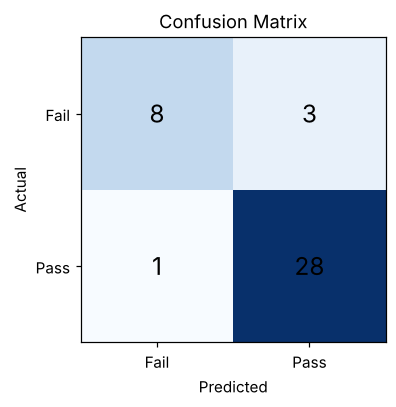

In [14]:
cm = confusion_matrix(y_test, y_pred, labels=["Fail", "Pass"])
plt.figure(figsize=(4.2, 3.6))
plt.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=16, color="black")
plt.xticks([0, 1], ["Fail", "Pass"]); plt.yticks([0, 1], ["Fail", "Pass"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
plt.show()

Assignment_Score    0.615
Attendance          0.656
Previous_Marks      1.019
Study_Hours         1.498
dtype: float64


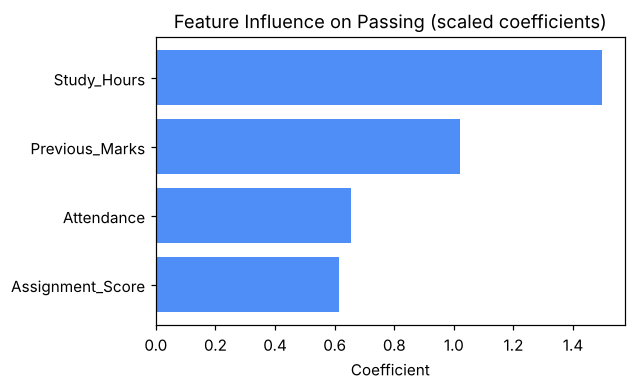

In [15]:
# Which features matter most? (coefficients of the trained model)
coef = pd.Series(model.coef_[0], index=X.columns).sort_values()
print(coef.round(3))
plt.figure(figsize=(5.5, 3.4))
plt.barh(coef.index, coef.values, color="#4f8ef7")
plt.title("Feature Influence on Passing (scaled coefficients)"); plt.xlabel("Coefficient")
plt.show()

In [16]:
# Predict for one new student
new_student = pd.DataFrame([[6, 85, 72, 70]], columns=X.columns)   # 6 hrs, 85% attendance, 72 marks, 70 assignment
prediction = model.predict(scaler.transform(new_student))[0]
prob_pass = model.predict_proba(scaler.transform(new_student))[0][list(model.classes_).index("Pass")]
print("Study Hours: 6 | Attendance: 85% | Previous Marks: 72 | Assignment Score: 70")
print("Prediction:", prediction.upper(), f"(probability of passing = {prob_pass:.2f})")

Study Hours: 6 | Attendance: 85% | Previous Marks: 72 | Assignment Score: 70
Prediction: PASS (probability of passing = 0.99)


### Explanation of the model output
- **Actual vs Predicted table:** compares the true result of test students with what the model predicted.
- **Accuracy:** the percentage of test students predicted correctly.
- **Confusion matrix:** shows correct predictions on the diagonal and mistakes off the diagonal.
- **Coefficients:** a positive value means that increasing the feature increases the chance of passing.